# PL6 · IA Generativa
## Pré-treino e pós-treino na prática (120 min)

**Mestrado em IA · Prática Laboratorial**

Nesta sessão vai reproduzir, em ponto pequeno, as decisões centrais do pipeline de um LLM:

| Parte | Exercício | Tempo | GPU |
|---|---|---|---|
| A · Pré-treino | 1. Curadoria: filtros heurísticos, deduplicação exata e MinHash-LSH | 25 min | não |
| | 2. Filtro de qualidade com classificador + contas de escala | 15 min | opcional |
| B · Pós-treino | 3. DPO de raiz: log-probabilidades, perda e um passo de gradiente | 20 min | sim |
| | 4. DPO com TRL + LoRA e análise das métricas | 25 min | sim |
| | 5. GRPO com recompensas verificáveis (GSM8K) | 20 min | sim |

**Ambiente recomendado:** Google Colab com GPU T4 (16 GB) — *Ambiente de execução → Alterar tipo → T4 GPU*.

**Convenções**
- `# TODO` assinala código a completar; as células seguintes têm `assert` para verificar a solução.
- ✍️ assinala perguntas a responder por escrito na própria célula (contam para a avaliação).
- Os tempos de treino indicados assumem uma T4; se ficar atrasado, reduza `max_steps`.

## 0 · Preparação (≈ 5 min)

In [1]:
# Instalação no Colab (≈ 1–2 min). Se o Colab pedir para reiniciar a sessão, reinicie e continue na célula seguinte.
!pip -q install "trl==0.19.1" "transformers>=4.51,<5" "peft>=0.15,<0.19" "datasets>=3.0,<5" "datasketch>=1.6" "accelerate>=1.4,<2"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, re, math, random, time, zlib, hashlib, gc
from collections import Counter, defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn.functional as F

SEMENTE = 0
random.seed(SEMENTE); np.random.seed(SEMENTE); torch.manual_seed(SEMENTE)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(sem GPU: as Partes 3–5 vão ser muito lentas)")

Dispositivo: cuda Tesla T4


---
# PARTE A · PRÉ-TREINO

## 1 · Curadoria de um corpus web (≈ 25 min)

Vamos usar ~3 000 documentos em português do **FineWeb-2** (`por_Latn`). Como este corpus **já foi filtrado e deduplicado**, vamos **injetar corrupção controlada** para termos verdade de base:

- 50 **duplicados exatos**;
- 100 **quase-duplicados** (palavras apagadas ou trocadas com uma dada taxa);
- 50 documentos **lixo** (menus, hashtags, repetição, *lorem ipsum*).

Assim conseguimos medir *precisão* e *recall* de cada etapa do funil.

In [3]:
from datasets import load_dataset

N_DOCS = 3000

def corpus_sintetico(n=N_DOCS, seed=0):
    """Plano B (sem internet): pseudo-texto com vocabulário português."""
    rng = random.Random(seed)
    vocab = ("o a de que e do da em um para com não uma os no se na por mais as dos como mas foi ao ele das tem "
             "seu sua ou ser quando muito há nos já está também só pelo pela até isso ela entre era depois sem mesmo "
             "cidade governo universidade estudo dados modelo sistema projeto trabalho tempo ano país mundo forma parte "
             "vida história caso problema lugar empresa grupo região investigação resultado processo").split()
    docs = []
    for _ in range(n):
        alvo, frases, w = rng.randint(30, 600), [], 0
        while w < alvo:
            k = rng.randint(6, 20); w += k
            frases.append(" ".join(rng.choice(vocab) for _ in range(k)).capitalize() + ".")
        docs.append(" ".join(frases))
    return docs

def carregar_corpus(n=N_DOCS):
    for nome, cfg in [("HuggingFaceFW/fineweb-2", "por_Latn"), ("HuggingFaceFW/fineweb", "sample-10BT")]:
        try:
            ds = load_dataset(nome, name=cfg, split="train", streaming=True)
            docs = [x["text"] for _, x in zip(range(n), ds)]
            print(f"Carregados {len(docs)} documentos de {nome} [{cfg}]")
            return docs
        except Exception as e:
            print(f"Falhou {nome} [{cfg}]: {type(e).__name__}")
    print("A usar corpus sintético (resultados qualitativamente semelhantes, textos sem sentido).")
    return corpus_sintetico(n)

docs = carregar_corpus()
print("Palavras por documento (mediana):", int(np.median([len(d.split()) for d in docs])))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/66 [00:00<?, ?it/s]

Carregados 3000 documentos de HuggingFaceFW/fineweb-2 [por_Latn]
Palavras por documento (mediana): 268


In [4]:
def quase_duplicado(texto, taxa, rng):
    """Apaga (taxa/2) ou substitui (taxa/2) cada palavra com probabilidade `taxa`."""
    palavras, out = texto.split(), []
    for p in palavras:
        u = rng.random()
        if u < taxa / 2:   continue
        elif u < taxa:     out.append(rng.choice(palavras))
        else:              out.append(p)
    return " ".join(out)

LIXO = [
    lambda rng: "\n".join("• " + rng.choice(["Início", "Contactos", "Loja", "Login", "Carrinho", "Termos", "Privacidade"]) for _ in range(40)),
    lambda rng: " ".join(rng.choice(["#promo", "#oferta", "...", "$$$", "#grátis", "#top"]) for _ in range(200)),
    lambda rng: "clique aqui para saber mais " * 40,
    lambda rng: "Lorem ipsum dolor sit amet, consectetur adipiscing elit. " * 20,
]

def corromper(docs, n_exatos=50, n_quase=100, n_lixo=50, taxa=0.02, seed=0):
    rng = random.Random(seed)
    corpus = [{"id": i, "texto": t, "tipo": "original", "origem": None} for i, t in enumerate(docs)]
    base = [d for d in corpus if len(d["texto"].split()) >= 100]
    for _ in range(n_exatos):
        d = rng.choice(base); corpus.append({"id": len(corpus), "texto": d["texto"], "tipo": "exato", "origem": d["id"]})
    for _ in range(n_quase):
        d = rng.choice(base); corpus.append({"id": len(corpus), "texto": quase_duplicado(d["texto"], taxa, rng), "tipo": "quase", "origem": d["id"]})
    for _ in range(n_lixo):
        corpus.append({"id": len(corpus), "texto": rng.choice(LIXO)(rng), "tipo": "lixo", "origem": None})
    rng.shuffle(corpus)
    return corpus

corpus = corromper(docs)
print(pd.Series([d["tipo"] for d in corpus]).value_counts())

original    3000
quase        100
lixo          50
exato         50
Name: count, dtype: int64


### 1.1 · Filtros heurísticos (estilo Gopher / C4)

Complete as regras em falta. Referência (Rae et al., 2021): 50–100 000 palavras; comprimento médio das palavras entre 3 e 10; rácio símbolos/palavras ≤ 0,1 (contar `#`, `...` e `…`); ≤ 90 % das linhas a começar por marcador; ≤ 30 % das linhas a acabar em reticências; ≥ 80 % das palavras com pelo menos uma letra; pelo menos 2 *stopwords*. E um filtro de repetição: a fração de caracteres ocupada pelo bigrama mais frequente deve ser ≤ 0,20.

In [5]:
STOP = {"de", "a", "o", "que", "e", "do", "da", "em", "um", "para", "é", "com", "não", "uma", "os", "no", "se", "na", "por",
        "the", "be", "to", "of", "and", "that", "have", "with"}

def filtro_gopher(texto, stop=STOP, limites_media=(3, 10), padrao_simbolos=r"#|\.{3}|…"):
    palavras = texto.split()
    n = len(palavras)
    if not (50 <= n <= 100_000):
        return False, "n_palavras"

    # A contagem de caracteres alfabéticos evita penalizar a pontuação adjacente às palavras.
    comprimentos = [len(re.sub(r"[^\w]", "", p, flags=re.UNICODE)) for p in palavras]
    media = np.mean(comprimentos)
    if not (limites_media[0] <= media <= limites_media[1]):
        return False, "comprimento_medio"

    simbolos = len(re.findall(padrao_simbolos, texto))
    if simbolos / n > 0.10:
        return False, "simbolos"

    linhas = [l.strip() for l in texto.splitlines() if l.strip()]
    if linhas:
        frac_marcadores = sum(bool(re.match(r"^[-*•]", l)) for l in linhas) / len(linhas)
        if frac_marcadores > 0.90:
            return False, "marcadores"
        frac_reticencias = sum(bool(re.search(r"(?:\.{3}|…)\s*$", l)) for l in linhas) / len(linhas)
        if frac_reticencias > 0.30:
            return False, "reticencias"

    frac_alfabeticas = sum(any(ch.isalpha() for ch in p) for p in palavras) / n
    if frac_alfabeticas < 0.80:
        return False, "palavras_alfabeticas"

    # Normaliza pontuação adjacente às stopwords e ignora maiúsculas.
    palavras_limpas = re.findall(r"\b\w+\b", texto.lower())
    if sum(p in stop for p in palavras_limpas) < 2:
        return False, "stopwords"
    return True, "ok"

def frac_top_ngrama(texto, n=2):
    p = texto.lower().split()
    grams = [" ".join(p[i:i + n]) for i in range(len(p) - n + 1)]
    if not grams:
        return 0.0
    g, c = Counter(grams).most_common(1)[0]
    return c * len(g.replace(" ", "")) / max(1, sum(len(x) for x in p))

def filtro_repeticao(texto, limiar=0.20):
    fracao = frac_top_ngrama(texto, n=2)
    return (False, "repeticao") if fracao > limiar else (True, "ok")

def aplicar_filtros(texto):
    ok, motivo = filtro_gopher(texto)
    if not ok:
        return motivo
    ok, motivo = filtro_repeticao(texto)
    return "ok" if ok else motivo

In [6]:
for d in corpus:
    d["filtro"] = aplicar_filtros(d["texto"])
tab = pd.crosstab(pd.Series([d["tipo"] for d in corpus], name="tipo"), pd.Series([d["filtro"] for d in corpus], name="resultado"))
display(tab)

lixo = [d for d in corpus if d["tipo"] == "lixo"]
assert sum(d["filtro"] != "ok" for d in lixo) == len(lixo), "Todo o lixo injetado devia ser removido pelos filtros."
print("✔ Todo o lixo foi removido.")

resultado,comprimento_medio,marcadores,ok,repeticao,reticencias,simbolos,stopwords
tipo,,,,,,,
exato,0,0,50,0,0,0,0
lixo,1,8,0,13,0,17,11
original,0,0,2999,0,0,1,0
quase,0,2,96,0,2,0,0


✔ Todo o lixo foi removido.


✍️ **P1.1** Que regras removem cada tipo de lixo? Há documentos *originais* removidos? Mostre 2 exemplos e discuta se são falsos positivos ou lixo real.

**✍️ Resposta:** Cada tipo de lixo foi apanhado por uma regra diferente (a tabela mostra a primeira regra que falhou). Dos 50 documentos de lixo, 17 caíram em simbolos (as hashtags e os "..."), 13 em repeticao ("clique aqui para saber mais" repetido), 11 em stopwords (o *lorem ipsum*, que não tem palavras funcionais portuguesas), 8 em marcadores (os menus, em que todas as linhas começam por "•") e 1 em comprimento_medio (fora do intervalo de 3 a 10 letras por palavra; provavelmente um documento de hashtags, em que "..." e "$$$" contam como palavras sem letras). Nenhum passou, por isso o assert é verdadeiro.

Dos 3000 originais só 1 foi removido, pela regra simbolos: um texto de blogue informal, cheio de reticências "…", que a regra confunde com ruído. É um falso positivo, porque é texto escrito por uma pessoa e não spam nem navegação, embora tenha pouco valor informativo. Como nos 3000 originais só há um rejeitado, o segundo exemplo vem da amostra alargada de 13 000 textos usada na secção 6.1 (desafio 4): a regra simbolos rejeita também uma sinopse ("Um menino chamado Darren Shan conhece um homem misterioso em um freak show…"), que é texto legível e, por isso, outro falso positivo, pelo mesmo motivo: as reticências "…" contam como símbolos. Nos dois casos o problema é contar "…" como ruído; só `#` e sequências de "..." isoladas deviam pesar. Por contraste, a rejeição por repetição da sequência artificial "clique aqui para saber mais" (lixo injetado) é correta. Também foram rejeitados 4 quase-duplicados (2 por marcadores e 2 por reticencias). Isto acontece porque a função quase_duplicado junta todas as linhas numa só, e as regras ao nível da linha passam a ver o documento inteiro como uma única linha que começa por marcador ou acaba em reticências.

In [7]:
for d in [d for d in corpus if d["tipo"] == "original" and d["filtro"] != "ok"][:2]:
    print(f'[{d["filtro"]}]', d["texto"][:300].replace("\n", " ⏎ "), "\n")

[simbolos] Muito bem…apos longo tempo de ausencia… ⏎ Arranjei uma casinha nova…. ⏎ Ja a tenho a algum tempo… Mas ainda esta a meio gás… ⏎ Se por acaso alguma alma quiser la ir dar um salto é so ir a ⏎ e ja agora ⏎ Se querem um blog virado pa informatica…têm aqui o blog do “meu patrão” ⏎ Que como “bom patrao” que é…anda me 



### 1.2 · Deduplicação exata

Normalize o texto (minúsculas, espaços colapsados), calcule um hash e mantenha, em cada grupo, o documento com **menor `id`** (o original).

In [8]:
def normalizar(texto):
    # Uniformizar caixa e substituir qualquer sequência de espaços por um só.
    return " ".join(texto.lower().split())

def dedup_exata(docs_):
    grupos = defaultdict(list)
    for d in docs_:
        grupos[hashlib.md5(normalizar(d["texto"]).encode("utf-8")).hexdigest()].append(d)
    manter = {min(g, key=lambda d: d["id"])["id"] for g in grupos.values()}
    return [d for d in docs_ if d["id"] in manter], [d for d in docs_ if d["id"] not in manter]

apos_filtros = [d for d in corpus if d["filtro"] == "ok"]
apos_exata, removidos = dedup_exata(apos_filtros)
print(f"{len(apos_filtros)} → {len(apos_exata)} documentos;", Counter(d["tipo"] for d in removidos))
assert Counter(d["tipo"] for d in removidos)["exato"] == 50
# Alguns duplicados podem ter sido rejeitados antes de chegar a esta etapa.
exatos_sobreviventes = sum(d["tipo"] == "exato" for d in apos_filtros)
exatos_eliminados = sum(d["tipo"] == "exato" for d in removidos)
assert exatos_eliminados == exatos_sobreviventes, "Há duplicados exatos sobreviventes não eliminados."
print(f"✔ Duplicados exatos sobreviventes eliminados: {exatos_eliminados}/{exatos_sobreviventes} (injetados: 50)")

3145 → 3094 documentos; Counter({'exato': 50, 'quase': 1})
✔ Duplicados exatos sobreviventes eliminados: 50/50 (injetados: 50)


### 1.3 · MinHash de raiz

Para dois conjuntos de *shingles* (5-gramas de palavras) $A$ e $B$:

$$J(A,B)=\frac{|A\cap B|}{|A\cup B|},\qquad P\big[\min h(A)=\min h(B)\big]=J(A,B)$$

Implemente a assinatura com $k$ funções de hash universais $h_j(x)=(a_j x+b_j) \bmod p$ e verifique que a fração de posições iguais estima $J$.

In [9]:
def shingles(texto, n=5):
    p = re.findall(r"\w+", texto.lower())
    return {" ".join(p[i:i + n]) for i in range(max(1, len(p) - n + 1))} if p else set()

def jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0

P_PRIMO = np.uint64(4294967311)  # primo > 2^32
def assinatura_minhash(sh, k=112, seed=1):
    rng = np.random.default_rng(seed)               # a mesma semente para todos os documentos!
    a = rng.integers(1, 2**31, size=k, dtype=np.uint64)
    b = rng.integers(0, 2**31, size=k, dtype=np.uint64)
    x = np.fromiter((zlib.crc32(s.encode()) for s in sh), dtype=np.uint64, count=len(sh))
    if not len(x):
        return np.full(k, np.iinfo(np.uint64).max, dtype=np.uint64)
    # Cada função de hash é h_j(x) = (a_j*x + b_j) mod P.
    # Os intervalos escolhidos mantêm os produtos dentro de uint64.
    hashes = (a[:, None] * x[None, :] + b[:, None]) % P_PRIMO
    return hashes.min(axis=1)

def jaccard_estimado(s1, s2):
    return float(np.mean(s1 == s2))

In [10]:
rng = random.Random(1)
base = [d["texto"] for d in apos_exata if len(d["texto"].split()) >= 150]
linhas = []
for taxa in [0.01, 0.03, 0.05, 0.10, 0.20]:
    for _ in range(5):
        a = rng.choice(base); b = quase_duplicado(a, taxa, rng)
        sa, sb = shingles(a), shingles(b)
        for k in [16, 112, 512]:
            linhas.append({"taxa": taxa, "k": k, "J_exato": jaccard(sa, sb),
                           "J_estimado": jaccard_estimado(assinatura_minhash(sa, k), assinatura_minhash(sb, k))})
res = pd.DataFrame(linhas); res["erro_abs"] = (res.J_estimado - res.J_exato).abs()
display(res.groupby("k").erro_abs.mean().rename("erro absoluto médio"))
assert res[res.k == 512].erro_abs.mean() < 0.05

,erro absoluto médio
k,
16,0.067333
112,0.022712
512,0.011285


✍️ **P1.2** Como varia o erro com $k$? Relacione com o desvio-padrão do estimador, $\sqrt{J(1-J)/k}$. Porque é que 5 % de palavras alteradas dão um $J$ tão baixo?

**✍️ Resposta:** O erro absoluto médio desce com k: 0,067 com k=16, 0,023 com k=112 e 0,011 com k=512, ou seja, cerca de 6 vezes menos de k=16 para k=512, o que é consistente com √32 ≈ 5,7. A fração de posições iguais entre duas assinaturas é uma média de k ensaios de Bernoulli com probabilidade J, por isso o seu desvio-padrão é √(J(1−J)/k) e diminui com 1/√k: para J=0,5 dá 0,125, 0,047 e 0,022 para k=16, 112 e 512. Para reduzir o erro a metade é preciso quadruplicar k.

Com 5 % de palavras alteradas o J cai para cerca de 0,67 (tabela da secção 1.4), porque cada palavra alterada estraga todos os shingles de 5 palavras que a contêm, ou seja, 5. A probabilidade de um shingle ficar intacto é (1−0,05)^5 ≈ 0,77 e, como J ≈ s/(2−s) com s a fração de shingles intactos, dá J ≈ 0,63, próximo do valor medido. O Jaccard sobre 5-gramas é muito mais sensível a pequenas edições do que a percentagem de palavras alteradas sugere.

### 1.4 · LSH por bandas e curva em S

Divida a assinatura em $b$ bandas de $r$ linhas: dois documentos são **candidatos** se coincidirem em **todas** as linhas de **pelo menos uma** banda. Teoricamente:

$$P(\text{candidato}\mid s)=1-(1-s^{r})^{b}$$

O FineWeb usa $b=14$, $r=8$ ($k=112$).

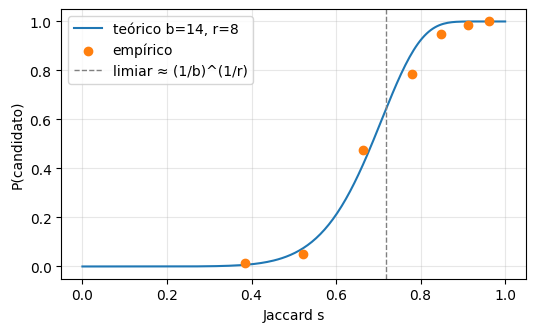

 taxa_edicao  Jaccard_medio  fracao_detetada
       0.005          0.961            1.000
       0.010          0.912            0.988
       0.020          0.849            0.950
       0.030          0.781            0.788
       0.050          0.665            0.475
       0.080          0.523            0.050
       0.120          0.385            0.012


In [11]:
def candidato_lsh(s1, s2, b=14, r=8):
    assert len(s1) == b * r == len(s2)
    # Basta existir uma banda em que as r linhas coincidam.
    a = np.asarray(s1).reshape(b, r)
    z = np.asarray(s2).reshape(b, r)
    return bool(np.any(np.all(a == z, axis=1)))

def p_teorico(s, b=14, r=8):
    return 1 - (1 - s ** r) ** b

rng = random.Random(2)
pontos = []
for taxa in [0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12]:
    Js, det = [], 0
    for _ in range(80):
        a = rng.choice(base); bq = quase_duplicado(a, taxa, rng)
        sa, sb = shingles(a), shingles(bq)
        Js.append(jaccard(sa, sb))
        det += candidato_lsh(assinatura_minhash(sa), assinatura_minhash(sb))
    pontos.append((np.mean(Js), det / 80))

s = np.linspace(0, 1, 200)
plt.figure(figsize=(6, 3.5))
plt.plot(s, p_teorico(s), label="teórico b=14, r=8")
plt.scatter(*zip(*pontos), color="C1", zorder=3, label="empírico")
plt.axvline((1 / 14) ** (1 / 8), ls="--", c="gray", lw=1, label="limiar ≈ (1/b)^(1/r)")
plt.xlabel("Jaccard s"); plt.ylabel("P(candidato)"); plt.legend(); plt.grid(alpha=.3); plt.show()

# Diagnóstico reprodutível para interpretar a pergunta P1.3.
print(pd.DataFrame({"taxa_edicao": [0.005,0.01,0.02,0.03,0.05,0.08,0.12],
                    "Jaccard_medio": [p[0] for p in pontos],
                    "fracao_detetada": [p[1] for p in pontos]}).round(3).to_string(index=False))

✍️ **P1.3** Os pontos empíricos seguem a curva? A partir de que taxa de edição os quase-duplicados deixam de ser apanhados? Que $(b,r)$ escolheria para apanhar $s\ge 0{,}6$ com o mesmo $k=112$?

**✍️ Resposta:** Os pontos seguem a curva em S teórica: a probabilidade de ser candidato sobe de perto de 0 para perto de 1 à volta de J ≈ 0,7, o que coincide com o limiar (1/14)^(1/8) ≈ 0,72. As pequenas diferenças devem-se a cada ponto ter só 80 pares. A fração detetada foi 100 % com 0,5 % de edição, 98,8 % com 1 %, 95 % com 2 %, 78,8 % com 3 %, 47,5 % com 5 %, 5 % com 8 % e 1,2 % com 12 %. Os quase-duplicados deixam por isso de ser apanhados pela maioria a partir de cerca de 5 % de palavras alteradas (J ≈ 0,67) e, com 8 %, quase nenhum é apanhado.

Para apanhar s ≥ 0,6 com os mesmos k=112 escolheria b=28 bandas de r=4 linhas: o limiar passa a (1/28)^(1/4) ≈ 0,43 e a probabilidade de ser candidato a s=0,6 sobe de 21 % (com 14×8) para 98 %. O custo são mais falsos candidatos: a s=0,3 a probabilidade é cerca de 20 % e a s=0,4 cerca de 52 %, pelo que os candidatos teriam de ser confirmados com o Jaccard exato. Com b=56 e r=2 o limiar seria 0,13 e quase tudo seria candidato.

### 1.5 · Deduplicação à escala do corpus (datasketch)

In [12]:
from datasketch import MinHash, MinHashLSH

def minhash_ds(sh, k=112):
    m = MinHash(num_perm=k, seed=1)
    m.update_batch([s.encode("utf8") for s in sh])
    return m

def dedup_quase(docs_, b=14, r=8):
    lsh, mhs = MinHashLSH(num_perm=b * r, params=(b, r)), {}
    for d in docs_:
        mhs[d["id"]] = minhash_ds(shingles(d["texto"]), b * r); lsh.insert(d["id"], mhs[d["id"]])
    pai = {d["id"]: d["id"] for d in docs_}
    def raiz(x):
        while pai[x] != x:
            pai[x] = pai[pai[x]]; x = pai[x]
        return x
    for d in docs_:
        for c in lsh.query(mhs[d["id"]]):
            ra, rb = raiz(d["id"]), raiz(c)
            if ra != rb: pai[max(ra, rb)] = min(ra, rb)   # o representante é o menor id
    grupo = {d["id"]: raiz(d["id"]) for d in docs_}
    return [d for d in docs_ if grupo[d["id"]] == d["id"]], grupo

t0 = time.time()
final, grupo = dedup_quase(apos_exata)
quase = [d for d in apos_exata if d["tipo"] == "quase"]
recall = np.mean([grupo[d["id"]] != d["id"] for d in quase])
orig_rem = [d for d in apos_exata if d["tipo"] == "original" and grupo[d["id"]] != d["id"]]
print(f"{len(apos_exata)} → {len(final)} documentos em {time.time() - t0:.0f}s")
print(f"Recall nos quase-duplicados injetados: {recall:.1%}  |  originais removidos: {len(orig_rem)}")

3094 → 3005 documentos em 13s
Recall nos quase-duplicados injetados: 93.7%  |  originais removidos: 0


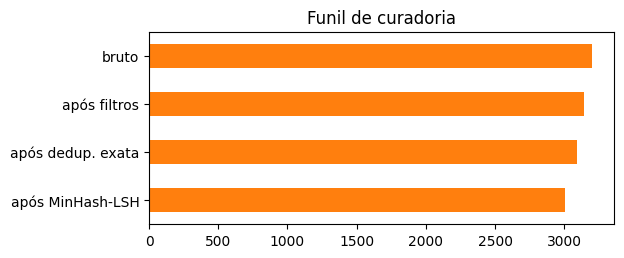

In [13]:
# Funil completo
funil = pd.Series({"bruto": len(corpus), "após filtros": len(apos_filtros), "após dedup. exata": len(apos_exata), "após MinHash-LSH": len(final)})
funil.plot.barh(figsize=(6, 2.5), color="C1"); plt.gca().invert_yaxis(); plt.title("Funil de curadoria"); plt.show()
for d in orig_rem[:2]:
    rep = next(x for x in apos_exata if x["id"] == grupo[d["id"]])
    print(f'J = {jaccard(shingles(d["texto"]), shingles(rep["texto"])):.2f}\n  A: {d["texto"][:160]!r}\n  B: {rep["texto"][:160]!r}\n')

✍️ **P1.4** Os originais removidos pelo MinHash são erros ou duplicados *naturais* do corpus? O que mudaria se a deduplicação fosse global sobre vários *snapshots* do Common Crawl (recorde o resultado do FineWeb)?

**✍️ Resposta:** O MinHash-LSH reduziu 3094 documentos para 3005, com recall de 93,7 % nos quase-duplicados injetados, e não removeu nenhum documento original, por isso não há pares para classificar como erro ou duplicado natural (a célula do funil não imprimiu nenhum). Se houvesse, o J impresso e os excertos A e B dariam a resposta: com J alto seriam duplicados naturais do corpus (notícias republicadas, páginas geradas a partir do mesmo modelo, avisos legais) e a remoção estaria certa; só seriam erros textos diferentes agrupados, o que pode acontecer porque a união dos pares é transitiva.

Se a deduplicação fosse global entre vários snapshots do Common Crawl, o resultado no FineWeb foi pior: deduplicar todos os snapshots em conjunto deu um modelo pior do que deduplicar cada snapshot em separado (a dedup global deixou cerca de 4 biliões de tokens, contra cerca de 20 biliões da individual). Uma explicação é que o que sobra nos snapshots mais antigos, depois de retirar o que reaparece nos mais recentes, é em média de pior qualidade. Por isso o FineWeb deduplica por snapshot, aceitando alguns duplicados entre snapshots.

## 2 · Filtro de qualidade e contas de escala (≈ 15 min)

### 2.1 · Classificador educativo do FineWeb-Edu

O `HuggingFaceFW/fineweb-edu-classifier` é um regressor (embeddings Snowflake-Arctic + cabeça linear) treinado com ~450 mil notas 0–5 atribuídas pelo Llama-3-70B. O FineWeb-Edu mantém os documentos com nota arredondada ≥ 3.

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/804 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/27468 [00:00<?, ?it/s]

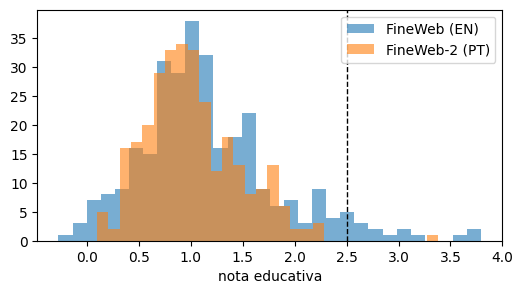

Fração com nota ≥ 3 — EN: 4.7% | PT: 0.3%

[3.69] Was The Race To The Moon Real?; June 1994; Scientific American Magazine; by Logsdon, Dupas; 8 Page(s) Twenty-five years ago, on July 20, 1969, Neil A. Armstrong took the first footsteps on the surface of the moon. That event marked a political and te

[3.80] Imagine a human spacecraft crew voyaging through space. A satellite sends a warning; energetic particles are being accelerated from the sun's corona, sending dangerous radiation toward their spacecraft, but the crew isn't worried. Long before their j

[-0.27] Short Dressesfrom £39 FURTHER REDUCTIONSShop All Sale Jackets & Coatsfrom £35 Our New In pieces are perfect to keep your wardrobe refreshed. Find a look you love in our latest lookbooks. Join the party on social media and get the lowdown on all thing

[-0.05] Her warm-weather faves, with a glittery new look she'll flip for! - Soft rubber footbeds are coated with sugar glitter - Flexible transparent plastic straps are infused wi

In [14]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
CLS = "HuggingFaceFW/fineweb-edu-classifier"
tok_c = AutoTokenizer.from_pretrained(CLS)
clf = AutoModelForSequenceClassification.from_pretrained(CLS).to(DEVICE).eval()

@torch.no_grad()
def nota_edu(textos, bs=16):
    notas = []
    for i in range(0, len(textos), bs):
        enc = tok_c(textos[i:i + bs], return_tensors="pt", padding="longest", truncation=True, max_length=512).to(DEVICE)
        notas += clf(**enc).logits.squeeze(-1).float().cpu().tolist()
    return np.array(notas)

en = load_dataset("HuggingFaceFW/fineweb", name="sample-10BT", split="train", streaming=True)
docs_en = [x["text"] for _, x in zip(range(300), en)]
notas_en = nota_edu(docs_en)
notas_pt = nota_edu([d["texto"] for d in final[:300]])

plt.figure(figsize=(6, 3)); plt.hist(notas_en, bins=30, alpha=.6, label="FineWeb (EN)"); plt.hist(notas_pt, bins=30, alpha=.6, label="FineWeb-2 (PT)")
plt.axvline(2.5, c="k", ls="--", lw=1); plt.legend(); plt.xlabel("nota educativa"); plt.show()
print(f"Fração com nota ≥ 3 — EN: {(notas_en >= 2.5).mean():.1%} | PT: {(notas_pt >= 2.5).mean():.1%}")
for i in list(np.argsort(notas_en)[-2:]) + list(np.argsort(notas_en)[:2]):
    print(f"\n[{notas_en[i]:.2f}]", docs_en[i][:250].replace("\n", " "))

✍️ **P2.1** Que fração passa o limiar? Que características têm os documentos com nota alta e baixa? O que acontece com os documentos em português e que viés isso introduziria num corpus multilingue?

**✍️ Resposta:** Passaram o limiar (nota ≥ 2,5, que arredonda para 3) 14 dos 300 textos ingleses (4,7 %) e 1 dos 300 portugueses (0,3 %). Os textos de nota alta eram explicativos e informativos, do tipo manual ou divulgação científica (um artigo da Scientific American sobre a corrida à Lua, nota 3,69, e um texto sobre radiação espacial, 3,80); os de nota baixa eram publicidade e páginas de lojas online (uma loja de roupa, −0,27, e uma listagem de calçado, −0,05).

O classificador foi treinado com notas dadas por um LLM a páginas em inglês e usa *embeddings* sobretudo ingleses, por isso tende a dar notas mais baixas ao português mesmo quando o texto é educativo. Os 0,3 % contra 4,7 % são coerentes com isso (as amostras são diferentes, por isso não o provam por si só). Usar um único limiar num corpus multilingue faria o português quase desaparecer e o corpus filtrado ficaria dominado pelo inglês. Alternativas são limiares por língua (por exemplo por percentil) ou classificadores treinados em cada língua.

### 2.2 · Calculadora de pré-treino

Implemente as funções e responda às perguntas. Use o pico denso BF16 da H100 (989 TFLOP/s).

In [15]:
def flops_treino(N, D):
    """Aproximação para o custo de pré-treino de um transformer denso."""
    return 6 * N * D

def dias_treino(N, D, n_gpus, pico=989e12, mfu=0.40):
    """Tempo efetivo: FLOPs / (GPUs × FLOPs/s × utilização), em dias."""
    if n_gpus <= 0 or not (0 < mfu <= 1):
        raise ValueError("n_gpus > 0 e 0 < mfu <= 1 são necessários")
    return flops_treino(N, D) / (n_gpus * pico * mfu * 86400)

def memoria_estados_gb(psi, nd=1, estagio=0, K=12):
    """Memória por GPU em GB decimais, sem ativações ou overhead.
    ZeRO-0: sem partição; ZeRO-1: partilha estados do otimizador;
    ZeRO-2: partilha também gradientes; ZeRO-3: partilha também os pesos.
    """
    if nd < 1 or estagio not in (0, 1, 2, 3):
        raise ValueError("nd >= 1 e estagio em {0,1,2,3}")
    bytes_por_parametro = {
        0: 4 + K,
        1: 4 + K / nd,
        2: 2 + (2 + K) / nd,
        3: (4 + K) / nd,
    }[estagio]
    return psi * bytes_por_parametro / 1e9

assert abs(flops_treino(405e9, 15.6e12) / 3.8e25 - 1) < 0.02
assert abs(dias_treino(70e9, 15e12, 2048) - 90) < 2
assert memoria_estados_gb(70e9, 64, 3) == 17.5
print("✔ Calculadora correta")

✔ Calculadora correta


In [16]:
# Q-a) Quantas H100 para treinar um 8B com 15T tokens em 30 dias com MFU de 40%?
N, D, prazo_dias, pico, mfu = 8e9, 15e12, 30, 989e12, 0.40
n_gpus = math.ceil(flops_treino(N, D) / (prazo_dias * 86400 * pico * mfu))
print("GPUs necessárias:", n_gpus)
print("Duração estimada:", round(dias_treino(N, D, n_gpus, pico, mfu), 2), "dias")

# Q-b) Afinação completa com Adam numa T4 (16 GB): cabe um 0,5B? E um 7B?
for psi in [0.5e9, 7e9]:
    print(f"{psi/1e9:.1f}B → {memoria_estados_gb(psi):.0f} GB só em estados (sem ativações)")

GPUs necessárias: 703
Duração estimada: 29.96 dias
0.5B → 8 GB só em estados (sem ativações)
7.0B → 112 GB só em estados (sem ativações)


✍️ **P2.2** Interprete os resultados de (a) e (b). Porque é que, nas Partes 4–5, usamos LoRA mesmo num modelo de 0,5B?

**✍️ Resposta:** (a) Treinar um modelo de 8B com 15 biliões de tokens custa cerca de 6·N·D = 7,2×10²³ FLOPs. Uma H100 com MFU de 40 % rende cerca de 3,96×10¹⁴ FLOP/s e, para acabar em 30 dias, são precisas 703 GPUs (cerca de 88 nós de 8). É uma estimativa otimista: um MFU de 40 % é difícil de manter e a conta ignora falhas, *checkpoints* e comunicação. Com um MFU real mais baixo seriam precisas mais GPUs (o número cresce com 1/MFU).

(b) Com Adam em precisão mista cada parâmetro ocupa 16 bytes (2 do peso, 2 do gradiente e 12 dos estados do otimizador), o que dá 8 GB para 0,5B e 112 GB para 7B, sem contar ativações. O de 7B não cabe numa T4 de 16 GB (só repartido, por exemplo com ZeRO-3 em pelo menos 8 GPUs, ficando 14 GB por GPU). O de 0,5B cabe no papel, mas as ativações, o contexto CUDA e a fragmentação deixam pouca folga.

Usa-se LoRA mesmo no 0,5B porque os pesos base ficam congelados (cerca de 1 GB em 16 bits) e só se treinam cerca de 1,75 % dos parâmetros (8,8 M, como o TRL imprimiu), pelo que os gradientes e os estados do Adam ocupam muito pouco. Além disso, no DPO e no GRPO a referência é o próprio modelo com os adaptadores desligados, sem uma segunda cópia na memória.

---
# PARTE B · PÓS-TREINO

## 3 · DPO de raiz (≈ 20 min)

$$\mathcal{L}_{\text{DPO}}=-\log\sigma\!\Big(\beta\log\frac{\pi_\theta(y_w|x)}{\pi_{\text{ref}}(y_w|x)}-\beta\log\frac{\pi_\theta(y_l|x)}{\pi_{\text{ref}}(y_l|x)}\Big)$$

Usamos `Qwen/Qwen2.5-0.5B-Instruct` como política e como referência.

In [17]:
from transformers import AutoTokenizer, AutoModelForCausalLM
MODELO = "Qwen/Qwen2.5-0.5B-Instruct"
BF16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
tok = AutoTokenizer.from_pretrained(MODELO)
politica = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.float32).to(DEVICE)
referencia = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.float32).to(DEVICE).eval()
for p in referencia.parameters(): p.requires_grad_(False)
print(f"{sum(p.numel() for p in politica.parameters())/1e6:.0f}M parâmetros")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

494M parâmetros


### 3.1 · Log-probabilidade de uma resposta

$\log\pi(y|x)=\sum_t \log\pi(y_t\mid x,y_{<t})$ — **só nos tokens da resposta** (incluindo o fim de turno). Atenção ao desvio de uma posição entre *logits* e alvos.

In [18]:
def logprob_resposta(modelo, prompt, resposta, grad=False):
    txt_p = tok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    ids_p = tok(txt_p, add_special_tokens=False, return_tensors="pt").input_ids
    ids_r = tok(resposta + tok.eos_token, add_special_tokens=False, return_tensors="pt").input_ids
    ids = torch.cat([ids_p, ids_r], dim=1).to(modelo.device)
    with torch.set_grad_enabled(grad):
        logits = modelo(ids).logits[:, :-1].float()  # logits[t] prevê ids[t+1]
        alvo = ids[:, 1:]
        lp = torch.log_softmax(logits, -1).gather(-1, alvo.unsqueeze(-1)).squeeze(-1)
        # Na matriz de alvos, as primeiras len(ids_p)-1 posições pertencem ao prompt.
        inicio_resposta = ids_p.shape[1] - 1
        mascara = torch.zeros_like(lp, dtype=torch.bool)
        mascara[:, inicio_resposta:] = True
        return lp.masked_select(mascara).sum()

### 3.2 · A perda

In [19]:
def perda_dpo(lp_pol_w, lp_pol_l, lp_ref_w, lp_ref_l, beta=0.1):
    """Devolve (perda, recompensa implícita de y_w, recompensa implícita de y_l)."""
    rw = beta * (lp_pol_w - lp_ref_w)
    rl = beta * (lp_pol_l - lp_ref_l)
    # -log(sigmoid(x)) == softplus(-x): mais estável numericamente.
    perda = F.softplus(-(rw - rl))
    return perda, rw, rl

# Verificação com o Exercício II da aula teórica: diferenças +2 e −1, β = 0,1  →  perda ≈ 0,554
L, rw, rl = perda_dpo(torch.tensor(2.), torch.tensor(-1.), torch.tensor(0.), torch.tensor(0.))
assert abs(L.item() - 0.5544) < 1e-3
print(f"perda = {L.item():.4f}   peso do gradiente σ(r_l − r_w) = {torch.sigmoid(rl - rw).item():.3f}")

perda = 0.5544   peso do gradiente σ(r_l − r_w) = 0.426


In [20]:
PROMPT = "Explica em duas frases o que é a deduplicação de dados no pré-treino de LLMs."
Y_W = ("É a remoção de documentos repetidos ou quase repetidos do corpus de treino. Evita que o modelo memorize "
       "texto duplicado e poupa compute, além de reduzir a contaminação de benchmarks.")
Y_L = "Deduplicação é quando os dados são duplicados para o modelo aprender melhor."

lp = {nome: logprob_resposta(m, PROMPT, y).item() for nome, m, y in
      [("pol_w", politica, Y_W), ("pol_l", politica, Y_L), ("ref_w", referencia, Y_W), ("ref_l", referencia, Y_L)]}
L0, _, _ = perda_dpo(torch.tensor(lp["pol_w"]), torch.tensor(lp["pol_l"]), torch.tensor(lp["ref_w"]), torch.tensor(lp["ref_l"]))
print(lp); print(f"perda inicial = {L0.item():.4f}   (log 2 = {math.log(2):.4f})")

{'pol_w': -137.22607421875, 'pol_l': -64.95844268798828, 'ref_w': -137.22607421875, 'ref_l': -64.95844268798828}
perda inicial = 0.6931   (log 2 = 0.6931)


✍️ **P3.1** Porque é que a perda inicial é exatamente $\log 2$? Qual das duas respostas tem maior $\log\pi$ e porque é que isso **não** significa que o modelo a prefira?

**✍️ Resposta:** No início a política e a referência são o mesmo modelo, com os mesmos pesos, por isso as duas razões logarítmicas são zero e as recompensas implícitas são r_w = r_l = 0. A perda fica −log σ(0) = −log(0,5) = log 2 ≈ 0,6931, qualquer que seja o par.

A resposta com maior log π é a rejeitada y_l (−64,96, contra −137,23 da preferida y_w). Isto acontece sobretudo porque é muito mais curta: log π(y|x) é uma soma de termos negativos, um por token, e uma resposta com menos tokens acumula menos. Não significa que o modelo a prefira, porque sequências de comprimentos diferentes não se comparam pela soma bruta e, além disso, o que o DPO usa é a variação face à referência (log π_θ − log π_ref), e não o valor absoluto.

### 3.3 · Dez passos de gradiente num único par

Implemente o ciclo de treino (SGD, `lr=1e-5`) e registe $\log\pi_\theta(y_w)$, $\log\pi_\theta(y_l)$ e a margem.

═══ SEM corte do gradiente (enunciado) ═══


,passo,perda,logp_w,logp_l,margem,norma_grad
0,0,0.693,-137.226,-64.958,0.000,221.656
1,1,0.325,-131.436,-68.748,0.958,117.490
2,2,0.210,-128.590,-70.839,1.452,79.136
3,3,0.156,-126.746,-72.281,1.780,59.657
4,4,0.124,-125.391,-73.385,2.026,47.898
5,5,0.103,-124.322,-74.282,2.223,40.030
6,6,0.088,-123.441,-75.038,2.386,34.395
7,7,0.077,-122.692,-75.692,2.527,30.159
8,8,0.068,-122.041,-76.269,2.650,26.859
9,9,0.061,-121.466,-76.786,2.759,24.214


═══ COM corte do gradiente (max_norm = 1,0) ═══


,passo,perda,logp_w,logp_l,margem,norma_grad
0,0,0.693,-137.226,-64.958,0.000,221.656
1,1,0.691,-137.201,-64.974,0.004,221.162
2,2,0.689,-137.176,-64.990,0.008,220.669
3,3,0.687,-137.152,-65.006,0.012,220.175
4,4,0.685,-137.127,-65.022,0.016,219.683
5,5,0.683,-137.102,-65.038,0.020,219.189
6,6,0.681,-137.077,-65.054,0.024,218.696
7,7,0.679,-137.052,-65.069,0.028,218.204
8,8,0.677,-137.028,-65.085,0.033,217.714
9,9,0.675,-137.003,-65.101,0.037,217.221


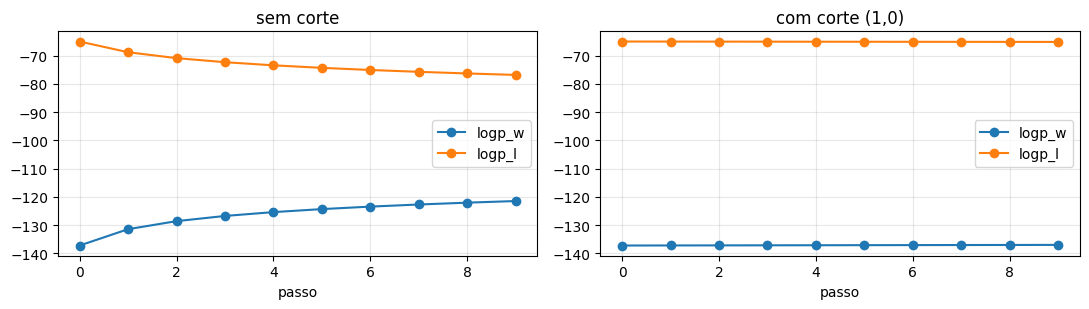

,sem corte,"com corte (1,0)"
margem final,2.759,0.037
perda final,0.061,0.675
Δ logπ(y_w),15.760,0.223
Δ logπ(y_l),-11.828,-0.143
norma do gradiente (passo 0),221.656,221.656


In [21]:
# Pesos iniciais guardados para repetir o ensaio nas mesmas condições (sem e com corte de gradiente)
estado0 = {k: v.detach().clone() for k, v in politica.state_dict().items()}

def treinar_dpo(clip=None, passos=10, lr=1e-5):
    """10 passos de SGD no par (y_w, y_l). clip=None → SEM corte do gradiente (como no enunciado); clip=1.0 → com corte à norma 1."""
    politica.load_state_dict(estado0)
    otim = torch.optim.SGD(politica.parameters(), lr=lr)
    hist = []
    for passo in range(passos):
        politica.train()
        otim.zero_grad(set_to_none=True)
        lw = logprob_resposta(politica, PROMPT, Y_W, grad=True)
        ll = logprob_resposta(politica, PROMPT, Y_L, grad=True)
        perda, rw, rl = perda_dpo(lw, ll, lw.new_tensor(lp["ref_w"]), ll.new_tensor(lp["ref_l"]))
        hist.append({"passo": passo, "perda": perda.item(), "logp_w": lw.item(), "logp_l": ll.item(), "margem": (rw - rl).item()})
        perda.backward()
        # devolve a norma do gradiente ANTES do corte; com max_norm=inf só mede, não corta
        hist[-1]["norma_grad"] = torch.nn.utils.clip_grad_norm_(politica.parameters(), clip if clip else float("inf")).item()
        otim.step()
    return pd.DataFrame(hist)

h_sem = treinar_dpo(clip=None)     # enunciado: SGD simples, sem corte
h_com = treinar_dpo(clip=1.0)      # versão com corte do gradiente à norma 1 (para comparação)

print("═══ SEM corte do gradiente (enunciado) ═══"); display(h_sem.round(3))
print("═══ COM corte do gradiente (max_norm = 1,0) ═══"); display(h_com.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=False)
for a, (nome, d) in zip(ax, [("sem corte", h_sem), ("com corte (1,0)", h_com)]):
    d.plot(x="passo", y=["logp_w", "logp_l"], marker="o", ax=a); a.set_title(nome); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

resumo = pd.DataFrame({
    nome: {"margem final": d.margem.iloc[-1], "perda final": d.perda.iloc[-1],
           "Δ logπ(y_w)": d.logp_w.iloc[-1] - d.logp_w.iloc[0], "Δ logπ(y_l)": d.logp_l.iloc[-1] - d.logp_l.iloc[0],
           "norma do gradiente (passo 0)": d.norma_grad.iloc[0]}
    for nome, d in [("sem corte", h_sem), ("com corte (1,0)", h_com)]}).round(3)
display(resumo)

✍️ **P3.2** A margem cresce? O que acontece a $\log\pi_\theta(y_w)$ — sobe, desce ou fica? Relacione com o *deslocamento de verosimilhança* (Razin et al., 2024). Que papel tem $\beta$?

**✍️ Resposta:** Em ambas as execuções a margem cresce em todos os passos, mas a escala é muito diferente. **Sem corte do gradiente** (SGD simples, como no enunciado) a margem vai de 0 para ≈ 2,8 em 10 passos e a perda desce de 0,693 para ≈ 0,06. Nesse ensaio log π_θ(y_w) **sobe** ≈ 16 (de ≈ −137 para ≈ −121) e log π_θ(y_l) **desce** ≈ 12 (de ≈ −65 para ≈ −77); a margem é β·(16 + 12) ≈ 0,1 × 28 ≈ 2,8. A norma do gradiente no primeiro passo é ≈ 220, muito acima de 1. **Com clip_grad_norm_(1,0)** cada passo é reduzido mais de 200 vezes, e a margem só chega a ≈ 0,04 (Δ log π(y_w) ≈ +0,22 e Δ log π(y_l) ≈ −0,14). Ou seja, o corte explica por que razão a execução com clipping evolui muito menos. (Os valores exatos estão nas tabelas acima; os que cito são arredondados.)

Neste par, e com estes 10 passos, **não se observa deslocamento de verosimilhança**: a resposta preferida fica mais provável e não menos. Isso não contradiz Razin et al. (2024): o DPO só garante que a margem cresce, não que log π_θ(y_w) aumente. Aqui há um único par e a resposta preferida é muito diferente da rejeitada; com muitos pares, a massa de probabilidade pode sair de ambas as respostas. Na secção 4 o valor de logps/chosen registado desce de cerca de −349 para −489 enquanto a margem aumenta, mas são minibatches diferentes, por isso não prova por si só que as mesmas respostas ficaram menos prováveis; para o confirmar seria preciso avaliar um conjunto fixo de pares antes e depois do treino.

O β escala a recompensa implícita r = β·log(π_θ/π_ref) e controla a distância à referência. Com β maior, a perda satura mais depressa e o modelo fica mais perto da referência; com β menor tem mais liberdade para se afastar. O peso do gradiente é β·σ(r_l − r_w), que no início é 0,1 × 0,5 = 0,05.

In [22]:
del politica, referencia, estado0; gc.collect(); torch.cuda.empty_cache()   # libertar a GPU

## 4 · DPO com TRL + LoRA (≈ 25 min, ~6 min de treino)

Dados: 1 000 pares do `trl-lib/ultrafeedback_binarized`. A referência é o próprio modelo com os adaptadores LoRA desligados.

In [23]:
from datasets import load_dataset
from trl import DPOConfig, DPOTrainer
from peft import LoraConfig

pref = load_dataset("trl-lib/ultrafeedback_binarized", split="train").shuffle(seed=0).select(range(1000))
print(pref[0]["chosen"][-1]["content"][:200])

lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")
modelo = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.bfloat16 if BF16 else torch.float32)

CFG_DPO = dict(
    beta=0.1, learning_rate=5e-5, lr_scheduler_type="cosine", warmup_ratio=0.1,
    per_device_train_batch_size=2, gradient_accumulation_steps=4, max_steps=40,
    max_length=384, max_prompt_length=192, gradient_checkpointing=True,
    bf16=BF16, fp16=(DEVICE == "cuda" and not BF16),   # T4: fp16 misto. Se a perda der NaN, ponha fp16=False.
    logging_steps=5, save_strategy="no", report_to="none",
)
cfg_dpo = DPOConfig(output_dir="dpo-qwen05", **CFG_DPO)
treinador = DPOTrainer(model=modelo, args=cfg_dpo, train_dataset=pref, processing_class=tok, peft_config=lora)
treinador.model.print_trainable_parameters()
treinador.train()

README.md:   0%|          | 0.00/643 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/131M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/2.14M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/62135 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Hello! As a top-tier AI assistant, I'm here to help you with your question. 😊

As a nurse, effective communication with patients is crucial in providing quality care and building trust. Here are some 


... (4 outputs left out)

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:232: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


Step,Training Loss
5,0.693300
10,0.632000
15,0.563900
20,0.676700
25,0.706300
30,0.687600
35,0.572400
40,0.608400


TrainOutput(global_step=40, training_loss=0.6425850450992584, metrics={'train_runtime': 458.3469, 'train_samples_per_second': 0.698, 'train_steps_per_second': 0.087, 'total_flos': 0.0, 'train_loss': 0.6425850450992584, 'epoch': 0.32})

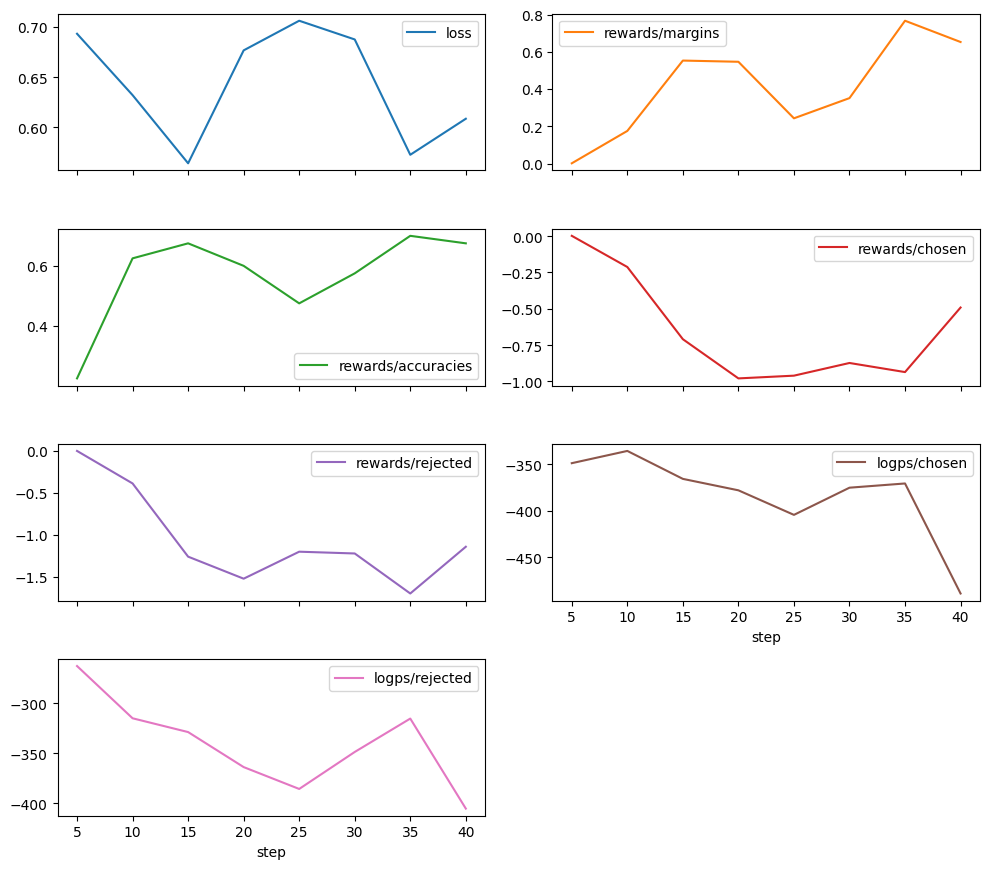

 step  loss  rewards/margins  rewards/accuracies  rewards/chosen  rewards/rejected  logps/chosen  logps/rejected
    5 0.693            0.001               0.225           0.002             0.001      -348.642        -262.979
   40 0.608            0.653               0.675          -0.491            -1.144      -489.300        -405.383


In [24]:
log = pd.DataFrame([h for h in treinador.state.log_history if "loss" in h and "train_runtime" not in h])
cols = [c for c in ["loss", "rewards/margins", "rewards/accuracies", "rewards/chosen", "rewards/rejected", "logps/chosen", "logps/rejected"] if c in log]
log.plot(x="step", y=cols, subplots=True, layout=(-1, 2), figsize=(10, 2.2 * math.ceil(len(cols) / 2)), legend=True); plt.tight_layout(); plt.show()
print(log[["step"] + cols].iloc[[0, -1]].round(3).to_string(index=False))

✍️ **P4.1** Descreva a evolução de `rewards/accuracies` e `rewards/margins`. As recompensas implícitas de *chosen* sobem ou descem? E `logps/chosen`? Interprete.

**✍️ Resposta:** rewards/accuracies (fração de pares em que a recompensa implícita da chosen é maior do que a da rejected) subiu de 0,225 (passo 5) para 0,675 (passo 40) e rewards/margins subiu de 0,001 para 0,653, ambas com ruído porque cada ponto é a média de poucos pares. O valor de 0,225 no primeiro registo significa que a chosen teve recompensa implícita superior à rejected em 22,5 % dos pares desse minibatch; sozinho, não permite atribuir uma causa à diferença.

As recompensas implícitas de chosen descem: rewards/chosen passou de 0,002 para −0,49, e a de rejected desce mais, para cerca de −1,14 (chosen menos margem). Também os valores registados de logps/chosen passam de aproximadamente −349 para −489. Como as métricas são calculadas sobre minibatches diferentes, não se pode concluir apenas dessa comparação que a probabilidade das mesmas respostas diminuiu. As recompensas relativas negativas e a melhoria das margens são compatíveis com deslocamento de verosimilhança, mas para o confirmar seria necessário comparar um conjunto fixo de respostas antes e depois do treino. Por isso, convém acompanhar logps/chosen, as margens e uma avaliação fixa, em vez de olhar só para a accuracy.

In [25]:
@torch.no_grad()
def gerar(modelo, prompt, max_new_tokens=150):
    ids = tok.apply_chat_template([{"role": "user", "content": prompt}], add_generation_prompt=True, return_tensors="pt").to(modelo.device)
    out = modelo.generate(ids, max_new_tokens=max_new_tokens, do_sample=False)
    return tok.decode(out[0, ids.shape[1]:], skip_special_tokens=True)

m = treinador.model.eval()
for pr in ["Give me three tips to write a good scientific abstract.", "Is it safe to eat raw chicken? Answer briefly."]:
    with m.disable_adapter():
        antes = gerar(m, pr)
    depois = gerar(m, pr)
    print(f"### {pr}\n--- ANTES ({len(antes.split())} palavras)\n{antes}\n--- DEPOIS ({len(depois.split())} palavras)\n{depois}\n")

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


### Give me three tips to write a good scientific abstract.
--- ANTES (115 palavras)
Certainly! Writing a scientific abstract is crucial for presenting your research effectively and clearly. Here are three key tips to help you create an engaging and informative scientific paper:

1. **Keep it concise**: Scientific papers should be brief but comprehensive. Aim for around 200-300 words per page. This allows readers to quickly grasp the main points of your work without having to read through the entire paper.

2. **Use clear and precise language**: Avoid jargon or overly technical terms unless they are essential to your field of study. Use simple language that is easy for non-specialists to understand. For example, instead of saying "We found [X]," say "We observed [X]."

3. **Provide context and background
--- DEPOIS (125 palavras)
Writing a scientific abstract is crucial for presenting your research effectively and clearly. Here are three key tips to help you create an engaging and info

In [26]:
# Viés de comprimento (P4.2): (1) nos dados e (2) nas respostas do modelo antes/depois.
comp_longa = np.mean([len(e["chosen"][-1]["content"]) > len(e["rejected"][-1]["content"]) for e in pref])
print(f"Pares em que a chosen é mais longa do que a rejected: {comp_longa:.0%}")

teste_pref = load_dataset("trl-lib/ultrafeedback_binarized", split="test").select(range(10))
N_MAX = 256
palavras, cortadas = {"antes": [], "depois": []}, {"antes": 0, "depois": 0}
with torch.no_grad():
    for e in teste_pref:
        ids = tok.apply_chat_template(e["chosen"][:-1], add_generation_prompt=True, return_tensors="pt").to(m.device)
        for nome in ["antes", "depois"]:
            if nome == "antes":
                with m.disable_adapter():
                    out = m.generate(ids, max_new_tokens=N_MAX, do_sample=False)[0, ids.shape[1]:]
            else:
                out = m.generate(ids, max_new_tokens=N_MAX, do_sample=False)[0, ids.shape[1]:]
            palavras[nome].append(len(tok.decode(out, skip_special_tokens=True).split()))
            cortadas[nome] += len(out) >= N_MAX
for nome in ["antes", "depois"]:
    print(f"{nome:6s}: {np.mean(palavras[nome]):.0f} palavras em média | {cortadas[nome]}/10 cortadas aos {N_MAX} tokens")

Pares em que a chosen é mais longa do que a rejected: 56%
antes : 115 palavras em média | 5/10 cortadas aos 256 tokens
depois: 117 palavras em média | 4/10 cortadas aos 256 tokens


✍️ **P4.2** Que diferenças observa (estilo, estrutura, comprimento)? Com 40 passos, o que é plausível ter mudado e o que não? Como verificaria se há viés de comprimento?

**✍️ Resposta:** As diferenças nas duas respostas são pequenas. No pedido sobre o resumo científico, a resposta passou de 115 para 125 palavras e ficou mais focada no objetivo, resultados e implicações. No exemplo sobre frango cru, passou de 111 para 119 palavras, mas manteve a afirmação errada de que é geralmente seguro comê-lo cru. Portanto, não houve uma melhoria evidente da segurança.

Nas 1000 preferências de treino, 56% das respostas escolhidas eram mais compridas do que as rejeitadas. Nos dez exemplos adicionais, a média passou de 115 para 117 palavras depois do DPO; 5 respostas antes e 4 depois chegaram ao limite de 256 tokens. Isto sugere uma diferença pequena no comprimento, mas estes exemplos não chegam para afirmar que existe um viés forte. Para testar melhor, usaria mais prompts, o mesmo limite de geração e uma avaliação de qualidade que também controlasse o comprimento das respostas. Com apenas 40 passos, é mais provável mudar o estilo e a organização das respostas do que melhorar muito o conhecimento ou o raciocínio.


In [27]:
del treinador, modelo, m; gc.collect(); torch.cuda.empty_cache()

## 5 · GRPO com recompensas verificáveis (≈ 20 min, ~8 min de treino)

### 5.1 · Vantagens relativas ao grupo

$$\hat A_i=\frac{r_i-\operatorname{mean}(r)}{\operatorname{std}(r)+\varepsilon}$$

In [28]:
def vantagens_grupo(r, normalizar_std=True, eps=1e-4):
    r = np.asarray(r, dtype=float)
    if r.size == 0:
        raise ValueError("O grupo não pode ser vazio")
    vantagens = r - r.mean()
    if normalizar_std:
        vantagens = vantagens / (r.std(ddof=0) + eps)
    return vantagens

print(vantagens_grupo([1, 0, 1, 0]).round(3),
      vantagens_grupo([1, 1, 1, 1]),
      vantagens_grupo([1, 0, 0, 0]).round(3))
assert np.allclose(vantagens_grupo([1, 0, 1, 0]), [1, -1, 1, -1], atol=1e-3)
assert np.allclose(vantagens_grupo([1, 1, 1, 1]), 0)

[ 1. -1.  1. -1.] [0. 0. 0. 0.] [ 1.732 -0.577 -0.577 -0.577]


✍️ **P5.1** Compare $[1,0,0,0]$ com $[1,1,1,0]$: que resposta recebe a maior vantagem absoluta em cada caso? Porque é que a divisão pelo desvio-padrão cria um viés de dificuldade (Dr. GRPO)?

**✍️ Resposta:** Em [1,0,0,0] (média 0,25, desvio-padrão 0,433) a única resposta certa recebe +1,732 e as erradas −0,577, por isso a maior vantagem em módulo é a da resposta certa, que é a rara. Em [1,1,1,0] as certas recebem +0,577 e a única errada recebe −1,732, e a maior é a da única errada. Em ambos os casos é a resposta diferente das outras que tem a vantagem de maior valor absoluto.

O viés vem de dividir pelo desvio-padrão do grupo. Para recompensas 0/1 com taxa de acerto p, o desvio é √(p(1−p)), que é máximo em p=0,5 e pequeno quando o problema é muito fácil ou muito difícil. Dividir por ele amplifica as vantagens desses grupos (sem normalizar, [1,0,0,0] daria +0,75 e −0,25), e as perguntas extremas passam a pesar mais no gradiente do que as de dificuldade média, que são as mais informativas. O Dr. GRPO retira essa divisão (scale_rewards=False).

### 5.2 · Funções de recompensa

O modelo deve terminar com `Resposta: <número>`. Implemente uma recompensa de **correção** (1,0 ou 0,0) e uma de **formato** (0,2). Na TRL, cada função recebe `completions` (lista de mensagens) e as colunas do dataset como argumentos nomeados.

In [29]:
SISTEMA = "Resolve o problema passo a passo e termina com uma linha no formato 'Resposta: <número>'."
RE_RESP = re.compile(r"Resposta:\s*\**\s*\$?\s*(-?[\d.,]+)", re.IGNORECASE)   # tolera "Resposta: **7**"

def _texto(c):
    return c[0]["content"] if isinstance(c, list) else c

def extrair_numero(texto):
    m = RE_RESP.findall(texto)
    if not m:
        return None
    try:
        # No GSM8K as vírgulas separam milhares. Para vírgulas decimais,
        # ver a discussão de limitações na P5.2.
        return float(m[-1].replace(",", "").rstrip("."))
    except ValueError:
        return None

def recompensa_correcao(completions, resposta, **kwargs):
    recompensas = []
    for comp, ref in zip(completions, resposta):
        valor = extrair_numero(_texto(comp))
        try:
            esperado = float(str(ref).replace(",", ""))
        except (ValueError, TypeError):
            esperado = None
        correto = (valor is not None and esperado is not None
                   and math.isclose(valor, esperado, rel_tol=1e-9, abs_tol=1e-9))
        recompensas.append(1.0 if correto else 0.0)
    return recompensas

def recompensa_formato(completions, **kwargs):
    return [0.2 if RE_RESP.search(_texto(c)) else 0.0 for c in completions]

testes = [[{"role": "assistant", "content": "3 + 4 = 7.\nResposta: 7"}],
          [{"role": "assistant", "content": "Acho que é 8.\nResposta: 8."}],
          [{"role": "assistant", "content": "São 1,000 euros. Resposta: $1,000"}],
          [{"role": "assistant", "content": "A resposta é 7."}]]
print(recompensa_correcao(testes, ["7", "7", "1000", "7"]), recompensa_formato(testes))
assert recompensa_correcao(testes, ["7", "7", "1000", "7"]) == [1.0, 0.0, 1.0, 0.0]

[1.0, 0.0, 1.0, 0.0] [0.2, 0.2, 0.2, 0.0]


✍️ **P5.2** Encontre pelo menos **duas** formas de a política obter recompensa sem resolver o problema, ou de ser penalizada injustamente (ex.: decimais com vírgula em português). Como corrigiria?

**✍️ Resposta:** (1) Formato explorável: a recompensa de formato (0,2) paga qualquer "Resposta: <número>" em qualquer parte do texto, mesmo sem raciocínio e com o número errado, por isso a política pode aprender a escrever "Resposta: 0" só para ganhar 0,2. Correção: exigir que seja a última linha (por exemplo com fullmatch), dar o formato só se a resposta estiver certa ou baixar o seu peso.

(2) Penalização injusta por convenção numérica: extrair_numero remove todas as vírgulas, por isso o decimal português "1,5" vira 15 e "1.000" (mil em português) vira 1,0, e respostas certas recebem 0. Correção: normalizar a convenção numérica (decidir se a vírgula é decimal ou separador de milhares), ou pedir à política que escreva só dígitos e ponto decimal. A resposta com o número a negrito ("Resposta: **7**") também era penalizada, e a expressão regular desta versão já a tolera.

(3) Truncagem: se a resposta é cortada pelo limite de tokens, não há "Resposta:" e a recompensa é 0 mesmo que o raciocínio esteja certo. Foi o que aconteceu na primeira execução (comprimento médio sempre igual ao limite), e leva a política a preferir respostas curtas sem raciocínio. Correção: aumentar max_completion_length e/ou pedir raciocínio curto.

### 5.3 · Dados, avaliação inicial e execução final

Na primeira execução (T4, `fp16` misto, instrução de formato só no *prompt* de sistema) o GRPO não aprendeu: o comprimento médio das respostas foi sempre o limite, todas as recompensas foram 0, `frac_reward_zero_std` foi 1 e a perda foi 0. Sem variação dentro dos grupos não há vantagem, e sem vantagem não há gradiente. Um diagnóstico em CPU mostrou que o *trainer* gerava texto válido mas **sem a linha `Resposta:`**, pelo que a recompensa era sempre 0.

Para a execução final alteram-se quatro coisas, todas verificáveis na célula seguinte:
1. **Precisão:** `bf16` só se a GPU o suporta nativamente; caso contrário, `float32` **sem** *autocast* `fp16` (o Qwen2.5 é instável em `fp16`, o que pode degenerar a geração dentro do *trainer*);
2. **LoRA sem *dropout*** (`lora_dropout=0`), porque o *dropout* fica ativo ao gerar em modo treino;
3. a **instrução de formato** vai também no turno do utilizador (o modelo pequeno obedece-lhe mais do que ao sistema);
4. 2 *prompts* × 4 respostas por passo (`per_device_train_batch_size=4` com acumulação 2), sem *gradient checkpointing*, o que mantém a *cache* de geração ligada.

Antes de treinar mede-se a exatidão inicial e sonda-se se há variação de recompensa dentro dos grupos.

In [30]:
from trl import GRPOConfig, GRPOTrainer
from peft import LoraConfig

# ---------------- Configuração ----------------
MODO_RAPIDO = False                    # True = 20 passos e 20 problemas de teste (≈ metade do tempo)
N_PASSOS    = 20 if MODO_RAPIDO else 40
N_TESTE     = 20 if MODO_RAPIDO else 30
MAX_COMP    = 256                      # tokens máximos por resposta (treino e avaliação)
N_GERACOES  = 4

bf16_nativo = DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 8      # Ampere ou superior
DTYPE_GRPO  = torch.bfloat16 if bf16_nativo else torch.float32                     # na T4: float32, sem autocast fp16
print(f"GPU: {torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU'} | bf16 nativo: {bf16_nativo} | dtype do modelo: {DTYPE_GRPO}")

SISTEMA_V2 = ("Resolve o problema de matemática com raciocínio curto (no máximo 5 linhas, sem repetir o enunciado). "
              "A última linha tem de ser exatamente 'Resposta: <número>', só com o número, sem unidades nem formatação.\n\n"
              "Exemplo:\nPergunta: A Ana tem 3 caixas com 4 maçãs cada e come 2 maçãs. Quantas maçãs lhe restam?\n"
              "3 caixas × 4 maçãs = 12 maçãs. 12 − 2 = 10.\nResposta: 10")
SUFIXO = "\n\nResolve em poucas linhas e termina com uma última linha exatamente neste formato: Resposta: <número>"

def preparar_v3(ex):
    return {"prompt": [{"role": "system", "content": SISTEMA_V2}, {"role": "user", "content": ex["question"] + SUFIXO}],
            "resposta": ex["answer"].split("####")[-1].strip().replace(",", "")}

gsm = load_dataset("openai/gsm8k", "main")
COLS = ["question", "answer"]
treino = gsm["train"].shuffle(seed=0).select(range(400)).map(preparar_v3, remove_columns=COLS)
teste  = gsm["test"].shuffle(seed=0).select(range(N_TESTE)).map(preparar_v3, remove_columns=COLS)

@torch.no_grad()
def exatidao(modelo, dados, max_new_tokens=MAX_COMP):
    """Devolve (exatidão, fração com 'Resposta:', fração de respostas cortadas no limite)."""
    modelo.eval(); acertos = formato = cortadas = 0
    for ex in dados:
        ids = tok.apply_chat_template(ex["prompt"], add_generation_prompt=True, return_tensors="pt").to(modelo.device)
        gen = modelo.generate(ids, max_new_tokens=max_new_tokens, do_sample=False)[0, ids.shape[1]:]
        out = tok.decode(gen, skip_special_tokens=True)
        acertos += recompensa_correcao([out], [ex["resposta"]])[0]
        formato += recompensa_formato([out])[0] > 0
        cortadas += len(gen) >= max_new_tokens
    n = len(dados); return acertos / n, formato / n, cortadas / n

@torch.no_grad()
def sondar(modelo, dados, n_prompts=6, G=N_GERACOES, temp=1.0):
    """Amostra G respostas por prompt e diz em quantos grupos há variação nas recompensas (sem variação não há sinal)."""
    modelo.eval(); sem_variacao, medias = 0, []
    for ex in list(dados)[:n_prompts]:
        ids = tok.apply_chat_template(ex["prompt"], add_generation_prompt=True, return_tensors="pt").to(modelo.device)
        out = modelo.generate(ids, max_new_tokens=MAX_COMP, do_sample=True, temperature=temp, top_k=0, top_p=1.0, num_return_sequences=G)
        textos = tok.batch_decode(out[:, ids.shape[1]:], skip_special_tokens=True)
        r = np.array(recompensa_correcao(textos, [ex["resposta"]] * G)) + np.array(recompensa_formato(textos))
        sem_variacao += float(r.std()) == 0.0; medias.append(r.mean())
    print(f"Sondagem: recompensa média {np.mean(medias):.2f} | grupos sem variação: {sem_variacao}/{n_prompts}")

# recompensa de depuração: devolve 0 (não altera o treino) e mostra o que o modelo gera DENTRO do GRPO nos 2 primeiros passos
_n_dbg = {"n": 0}
def debug_geracoes(completions, **kwargs):
    if _n_dbg["n"] < 2:
        for c in completions[:2]:
            t = _texto(c); print(f"[DEBUG passo {_n_dbg['n']}] {len(tok(t).input_ids)} tokens | …{t[-140:]!r}")
    _n_dbg["n"] += 1
    return [0.0] * len(completions)

modelo = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=DTYPE_GRPO).to(DEVICE)
t0 = time.time()
acc0 = exatidao(modelo, teste)
print(f"ANTES — exatidão: {acc0[0]:.0%} | formato: {acc0[1]:.0%} | cortadas no limite: {acc0[2]:.0%}   ({time.time()-t0:.0f}s)")
sondar(modelo, treino)   # se TODOS os grupos vierem sem variação, o treino fica parado: ver o aviso abaixo

GPU: Tesla T4 | bf16 nativo: False | dtype do modelo: torch.float32


README.md: 0.00B [00:00, ?B/s]

main/train-00000-of-00001.parquet:   0%|          | 0.00/2.31M [00:00<?, ?B/s]

main/test-00000-of-00001.parquet:   0%|          | 0.00/419k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/30 [00:00<?, ? examples/s]

ANTES — exatidão: 10% | formato: 60% | cortadas no limite: 7%   (81s)
Sondagem: recompensa média 0.16 | grupos sem variação: 2/6


In [31]:
lora_grpo = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.0, target_modules="all-linear", task_type="CAUSAL_LM")

cfg_grpo = GRPOConfig(
    output_dir="grpo-qwen05", learning_rate=5e-5, lr_scheduler_type="constant",
    per_device_train_batch_size=4, gradient_accumulation_steps=2, num_generations=N_GERACOES,   # 2 prompts × 4 respostas por passo
    max_prompt_length=384, max_completion_length=MAX_COMP, temperature=1.0,
    beta=0.04, loss_type="grpo", max_steps=N_PASSOS,
    gradient_checkpointing=False,
    bf16=bf16_nativo, fp16=False, use_cpu=(DEVICE == "cpu"),
    logging_steps=1, save_strategy="no", report_to="none",
)
treinador = GRPOTrainer(model=modelo, reward_funcs=[recompensa_correcao, recompensa_formato, debug_geracoes],
                        args=cfg_grpo, train_dataset=treino, processing_class=tok, peft_config=lora_grpo)
t0 = time.time()
treinador.train()
print(f"GRPO concluído em {(time.time()-t0)/60:.1f} min")

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


[DEBUG passo 0] 125 tokens | …'divide the overall carbon dioxide emissions by the emissions from plastic bags: 9600 ounces / 32 ounces per trip = 300 trips.\n\nResposta: 300'
[DEBUG passo 0] 5 tokens | …'Resposta: 8'


Step,Training Loss
1,0.000000
2,0.000500
3,0.000600
4,0.000700
5,0.000800
6,0.000700
7,0.001200
8,0.001300
9,0.001500
10,0.004600


[DEBUG passo 1] 120 tokens | …'acos / (6 * deslocamentos de animais de ferro). Vamos calcular com base em <assim sendo...>: racos = racos (total) / racoes / 6. Resposta: 6'
[DEBUG passo 1] 46 tokens | …'X raccoons × 6 = 84 raccoons. 84 = 6 × 14 raccoons. 84 = 14 raccoons. Resposta: 14'
GRPO concluído em 12.0 min


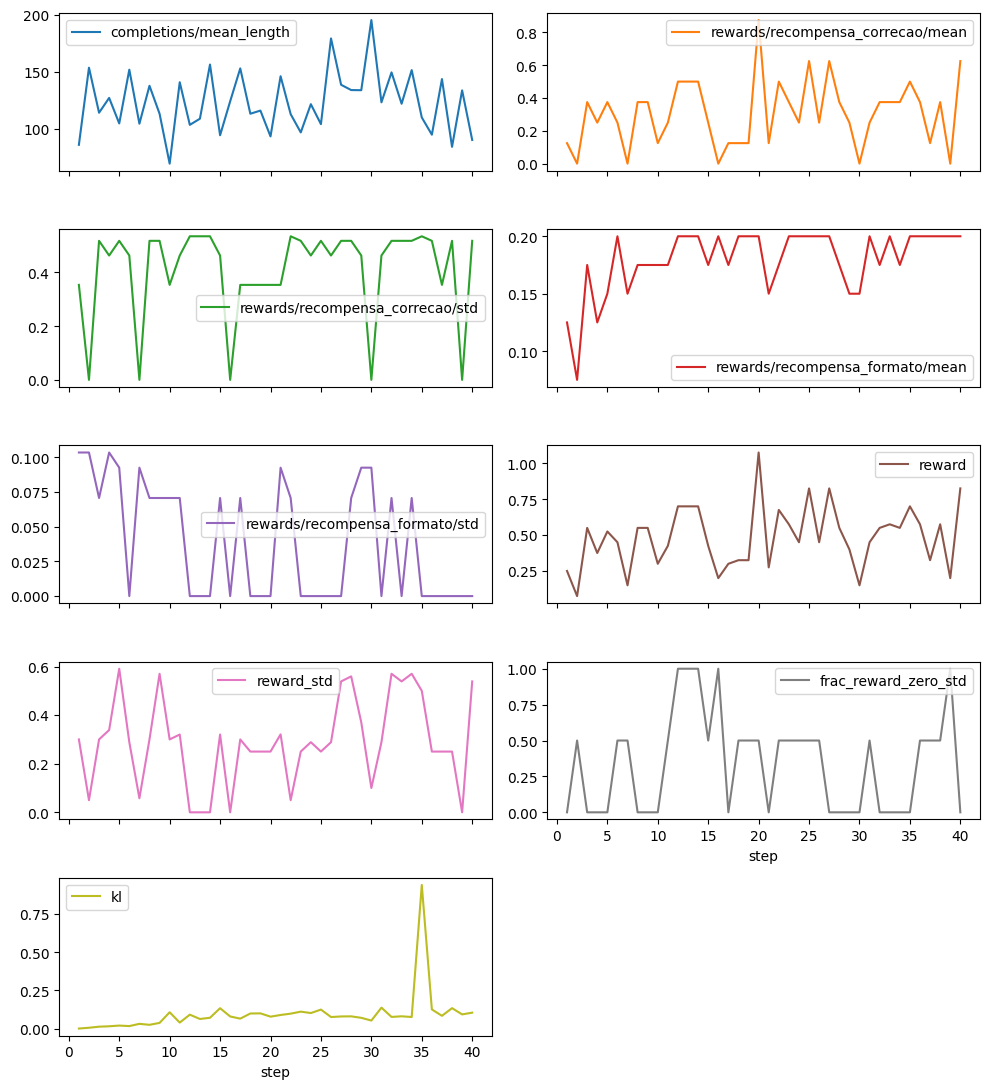

ANTES  — exatidão: 10% | formato: 60% | cortadas: 7%
DEPOIS — exatidão: 43% | formato: 93% | cortadas: 3%
(cada um dos 30 problemas vale 3.3 pontos percentuais)


,1.º quarto dos passos,último quarto
recompensa total,0.378,0.533
recompensa de correção,0.225,0.338
recompensa de formato,0.153,0.195
reward_std,0.310,0.376
fração de grupos com desvio nulo,0.150,0.300
KL,0.027,0.185
comprimento médio (tokens),116.125,120.175


Exatidão final 43.3% com erro-padrão ≈ 9.0% (n = 30); variação antes→depois: +33.3 pp, formato +33.3 pp.


In [32]:
log_main = pd.DataFrame([h for h in treinador.state.log_history if "train_runtime" not in h])
cols = [c for c in log_main.columns if any(k in c for k in ["reward", "kl", "mean_length", "zero_std", "entropy"])
        and "debug" not in c and log_main[c].notna().any()]
log_main.plot(x="step", y=cols, subplots=True, layout=(-1, 2), figsize=(10, 2.2 * math.ceil(len(cols) / 2))); plt.tight_layout(); plt.show()

acc1 = exatidao(treinador.model, teste)
print(f"ANTES  — exatidão: {acc0[0]:.0%} | formato: {acc0[1]:.0%} | cortadas: {acc0[2]:.0%}")
print(f"DEPOIS — exatidão: {acc1[0]:.0%} | formato: {acc1[1]:.0%} | cortadas: {acc1[2]:.0%}")
print(f"(cada um dos {N_TESTE} problemas vale {100/N_TESTE:.1f} pontos percentuais)")

# ---------------- Resumo numérico para escrever a P5.3 ----------------
def inicio_fim(nome):
    s = log_main[nome].dropna().to_numpy() if nome in log_main else np.array([])
    if not len(s): return float("nan"), float("nan")
    k = max(1, len(s) // 4); return s[:k].mean(), s[-k:].mean()

linhas = {"recompensa total": "reward", "recompensa de correção": "rewards/recompensa_correcao/mean",
          "recompensa de formato": "rewards/recompensa_formato/mean", "reward_std": "reward_std",
          "fração de grupos com desvio nulo": "frac_reward_zero_std", "KL": "kl", "comprimento médio (tokens)": "completions/mean_length"}
resumo5 = pd.DataFrame({k: inicio_fim(v) for k, v in linhas.items()}, index=["1.º quarto dos passos", "último quarto"]).T.round(3)
display(resumo5)

p = acc1[0]; ep = (p * (1 - p) / N_TESTE) ** 0.5
print(f"Exatidão final {p:.1%} com erro-padrão ≈ {ep:.1%} (n = {N_TESTE}); variação antes→depois: {100*(acc1[0]-acc0[0]):+.1f} pp, formato {100*(acc1[1]-acc0[1]):+.1f} pp.")
if resumo5.loc["fração de grupos com desvio nulo"].min() >= 0.99:
    print("⚠️ Todos os grupos tiveram desvio nulo: não houve sinal de aprendizagem. Vê as linhas [DEBUG …] acima antes de interpretar.")

✍️ **P5.3** Interprete as curvas: recompensa média, `reward_std`, fração de grupos com desvio nulo, KL e comprimento. A melhoria (se houver) vem da correção ou do formato? Com 30 exemplos de teste, quão confiável é a diferença?

**✍️ Resposta:** A recompensa média total subiu de 0,378 no primeiro quarto dos passos para 0,533 no último. O reward_std médio passou de 0,310 para 0,376, enquanto a fração de grupos sem variação de recompensa passou de 0,15 para 0,30. Apesar de esta última ter aumentado, não ficou em 1: houve grupos com respostas de recompensas diferentes, o que permitiu ao GRPO calcular vantagens úteis para o treino. A sondagem antes do treino também já mostrava alguma variação, com apenas 2 dos 6 grupos sem diferenças de recompensa.

O KL médio aumentou de 0,027 para 0,185, indicando que a política se afastou da referência durante o treino. O comprimento médio das respostas passou de cerca de 116 para 120 tokens, uma variação pequena face ao limite de 256. Na avaliação final, as respostas cortadas no limite diminuíram de 7% para 3%.

A melhoria não veio apenas de aprender o formato. A recompensa de correção passou de 0,225 para 0,338 (+0,113), enquanto a de formato passou de 0,153 para 0,195 (+0,042). Portanto, o maior aumento de recompensa veio da correção das respostas, embora o formato também tenha melhorado. Nos 30 problemas de teste, a exatidão passou de 10% para 43,3% e o cumprimento do formato de 60% para 93,3%. São melhorias de 33,3 pontos percentuais nos dois casos.

Os resultados são encorajadores, mas a amostra de teste é pequena: cada problema representa cerca de 3,3 pontos percentuais e, para uma exatidão final de 43,3%, o erro-padrão binomial é de aproximadamente 9 pontos percentuais. Além disso, a comparação antes/depois usa os mesmos problemas, pelo que uma análise estatística rigorosa deveria ter em conta os acertos individuais em cada momento. Para avaliar melhor a consistência desta melhoria, seria necessário testar mais problemas e repetir o treino com outras sementes.

## 6 · Desafios extra (para quem terminar cedo ou como trabalho de casa)

1. **Dr. GRPO vs GRPO:** repita a Parte 5 com `loss_type="dr_grpo"` e `scale_rewards=False`. Compare o comprimento das respostas.
2. **β = 0:** treine o GRPO sem KL. O que acontece à entropia e ao KL implícito?
3. **IPO:** na Parte 4, use `loss_type="ipo"` no `DPOConfig` e compare `logps/chosen`.
4. **Português:** adapte os filtros da Parte 1 a português (stopwords, comprimento médio) e meça quantos originais deixam de ser removidos.
5. **Hacking:** suba a recompensa de formato para 1,0 e observe se a correção piora.

## 6.1 · Desafio extra 4: filtros adaptados a português

Foram comparadas quatro configurações dos filtros em 13 000 textos do FineWeb-2 em português: o filtro original, mais stopwords portuguesas, limite inferior do comprimento médio de 2,5 e, por fim, uma variante que deixa de contar `…` como símbolo. Também se verificou se os 50 documentos de lixo continuavam a ser removidos.


In [33]:
STOP_PT = STOP | {
    "ao", "aos", "à", "às", "as", "dos", "das", "num", "numa", "nos", "nas", "pelo", "pela", "pelos", "pelas",
    "também", "já", "esta", "este", "estes", "estas", "esse", "essa", "isso", "isto", "ele", "ela", "eles", "elas",
    "foi", "são", "ser", "ter", "tem", "há", "pode", "podem", "depois", "antes", "sobre", "entre", "sem",
    "mais", "menos", "muito", "muita", "como", "onde", "quando", "porque", "mas", "até", "ou", "seu", "sua"
}
VARIANTES = {
    "A original":             dict(stop=STOP),
    "B + stopwords PT":       dict(stop=STOP_PT),
    "C + comprimento ≥ 2,5":  dict(stop=STOP_PT, limites_media=(2.5, 10)),
    "D + sem '…' nos símbolos": dict(stop=STOP_PT, limites_media=(2.5, 10), padrao_simbolos=r"#|\.{3}"),
}
def motivo(texto, **kw):
    ok, m_ = filtro_gopher(texto, **kw)
    if not ok: return m_
    ok, m_ = filtro_repeticao(texto)
    return "ok" if ok else m_

ds_pt = load_dataset("HuggingFaceFW/fineweb-2", name="por_Latn", split="train", streaming=True)
extra = [x["text"] for _, x in zip(range(10_000), ds_pt.skip(3000))]
orig_3000 = [d["texto"] for d in corpus if d["tipo"] == "original"]
lixo_txt = [d["texto"] for d in corpus if d["tipo"] == "lixo"]
todos = orig_3000 + extra

linhas = []
for nome, kw in VARIANTES.items():
    mot = [motivo(t, **kw) for t in todos]
    linhas.append({"variante": nome, "originais rejeitados": sum(x != "ok" for x in mot),
                   "% rejeitados": round(100 * np.mean([x != "ok" for x in mot]), 2),
                   "por simbolos": mot.count("simbolos"), "por stopwords": mot.count("stopwords"),
                   "por comprimento_medio": mot.count("comprimento_medio"),
                   "lixo removido (de 50)": sum(motivo(t, **kw) != "ok" for t in lixo_txt)})
display(pd.DataFrame(linhas).set_index("variante"))

rec = [t for t in todos if motivo(t, **VARIANTES["A original"]) != "ok" and motivo(t, **VARIANTES["D + sem '…' nos símbolos"]) == "ok"]
print(f"\nRecuperados pela variante D face à A: {len(rec)}")
for t in rec[:2]: print("-", t[:220].replace("\n", " ⏎ "), "\n")

Resolving data files:   0%|          | 0/66 [00:00<?, ?it/s]

,originais rejeitados,% rejeitados,por simbolos,por stopwords,por comprimento_medio,lixo removido (de 50)
variante,,,,,,
A original,8,0.06,2,0,0,50
B + stopwords PT,8,0.06,2,0,0,50
"C + comprimento ≥ 2,5",8,0.06,2,0,0,50
D + sem '…' nos símbolos,6,0.05,0,0,0,50



Recuperados pela variante D face à A: 2
- Muito bem…apos longo tempo de ausencia… ⏎ Arranjei uma casinha nova…. ⏎ Ja a tenho a algum tempo… Mas ainda esta a meio gás… ⏎ Se por acaso alguma alma quiser la ir dar um salto é so ir a ⏎ e ja agora ⏎ Se querem um blog virado pa 

- Um menino chamado Darren Shan conhece um homem misterioso em um freak show que acaba por ser um vampiro. Após uma série de eventos Darren deve deixar a sua vida normal para ir para a estrada com o Cirque Du Freak e torna 



**✍️ Resposta (desafio 4):** No conjunto de 13 000 textos, o filtro original rejeitou 8 documentos. Acrescentar stopwords portuguesas não alterou este número e baixar o limite do comprimento médio de 3 para 2,5 também não teve efeito. Quando deixei de contar `…` como símbolo, os rejeitados passaram de 8 para 6. Os dois textos recuperados tinham muitas reticências, mas continham texto legível, por isso podiam ser falsos positivos.

Nas quatro configurações, os 50 documentos de lixo injetados continuaram a ser rejeitados. Nesta amostra, as alterações às stopwords e ao comprimento médio não tiveram impacto; a diferença veio apenas do tratamento da pontuação. Isso não prova que ignorar `…` seja sempre melhor, porque também podemos deixar passar texto ruidoso. Seria preciso testar noutros conjuntos de documentos portugueses antes de alterar o filtro de forma definitiva.


## 📦 Entrega

Submeta este notebook **executado**, com todas as células ✍️ respondidas, até ao fim da semana. Critérios: código correto (40 %), qualidade das respostas e interpretação dos gráficos (45 %), desafio extra (15 %).